## Assignment no 13

## LightGBM (LGBM) vs XGBoost (XGBM)

Part : 1 Import Required Libraries

In [3]:
%pip install pandas numpy matplotlib seaborn scikit-learn lightgbm xgboost

Note: you may need to restart the kernel to use updated packages.


In [4]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV
)

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Machine learning models
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Suppress unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

# Set visualization style
sns.set_style("whitegrid")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("All libraries imported successfully!")

All libraries imported successfully!


Part 2 : Load the Dataset

In [5]:
columns = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
    'Outcome'
]

df = pd.read_csv("diabetes.csv", names=columns, header=0)

# Display first five records
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Dataset dimensions

In [6]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 768
Number of Columns: 9


Display first and last records

In [7]:
print("First Five Records:")
display(df.head())

print("\nLast Five Records:")
display(df.tail())

First Five Records:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Last Five Records:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


Dataset information

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


Statistical summary

In [9]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


PART 3 — Exploratory Data Analysis (EDA)

Check missing values

In [10]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

# Calculate missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing Percentage:")
print(missing_percentage.round(2))

Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Missing Percentage:
Pregnancies                 0.0
Glucose                     0.0
BloodPressure               0.0
SkinThickness               0.0
Insulin                     0.0
BMI                         0.0
DiabetesPedigreeFunction    0.0
Age                         0.0
Outcome                     0.0
dtype: float64


Missing value visualization

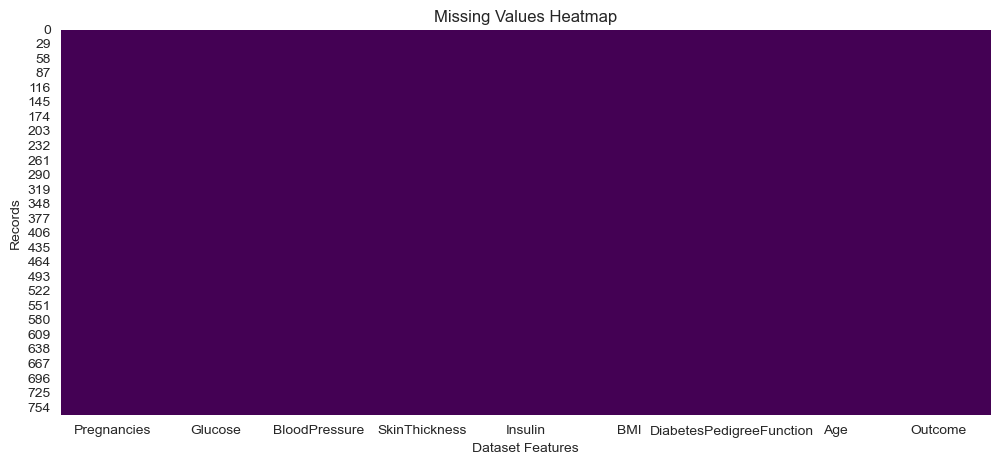

In [11]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Missing Values Heatmap")
plt.xlabel("Dataset Features")
plt.ylabel("Records")
plt.show()

Check duplicate records

In [12]:
# Count duplicate rows
print("Duplicate Records:", df.duplicated().sum())

# Display duplicates
display(df[df.duplicated()])

Duplicate Records: 0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome


Target variable distribution

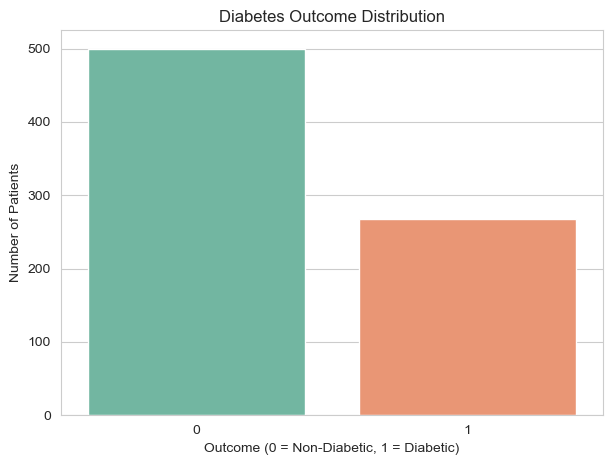

Outcome
0    500
1    268
Name: count, dtype: int64


In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Outcome",
    hue="Outcome",
    palette="Set2",
    legend=False
)

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = Non-Diabetic, 1 = Diabetic)")
plt.ylabel("Number of Patients")

plt.show()

print(df["Outcome"].value_counts())

Histograms

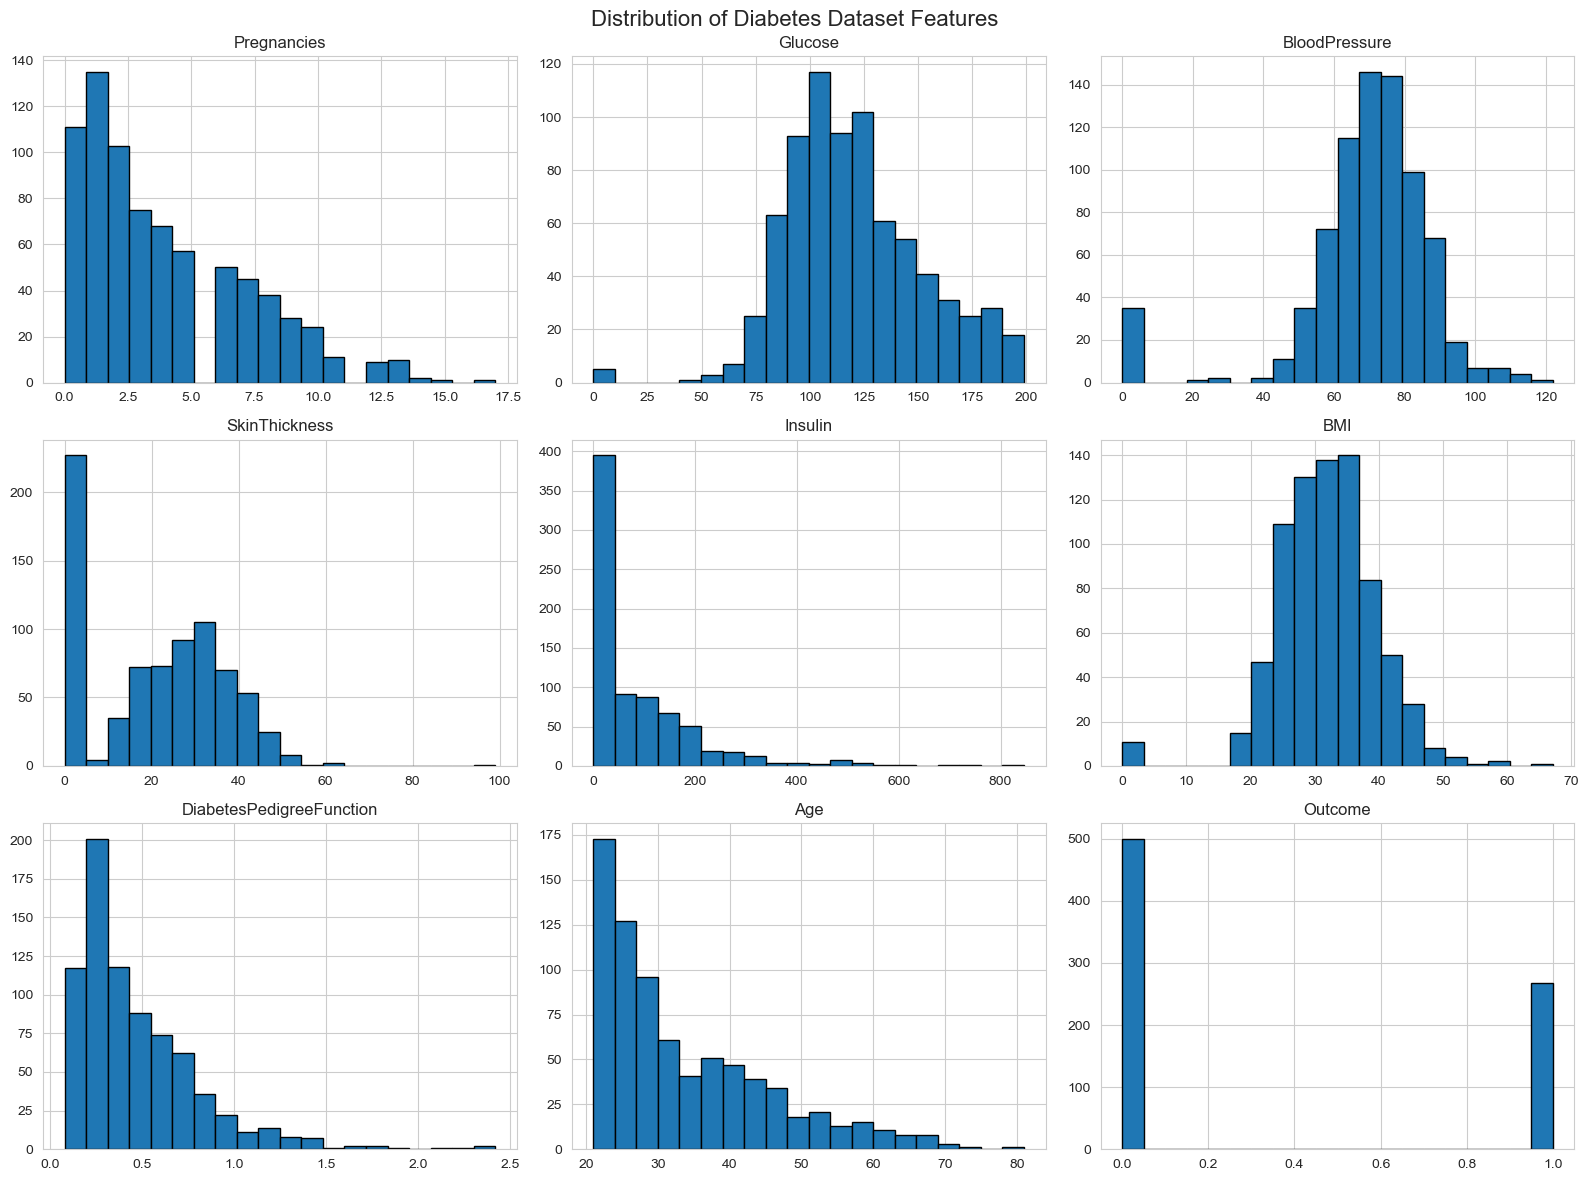

In [14]:
# Plot histograms for all numerical features
df.hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Diabetes Dataset Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

Box plots

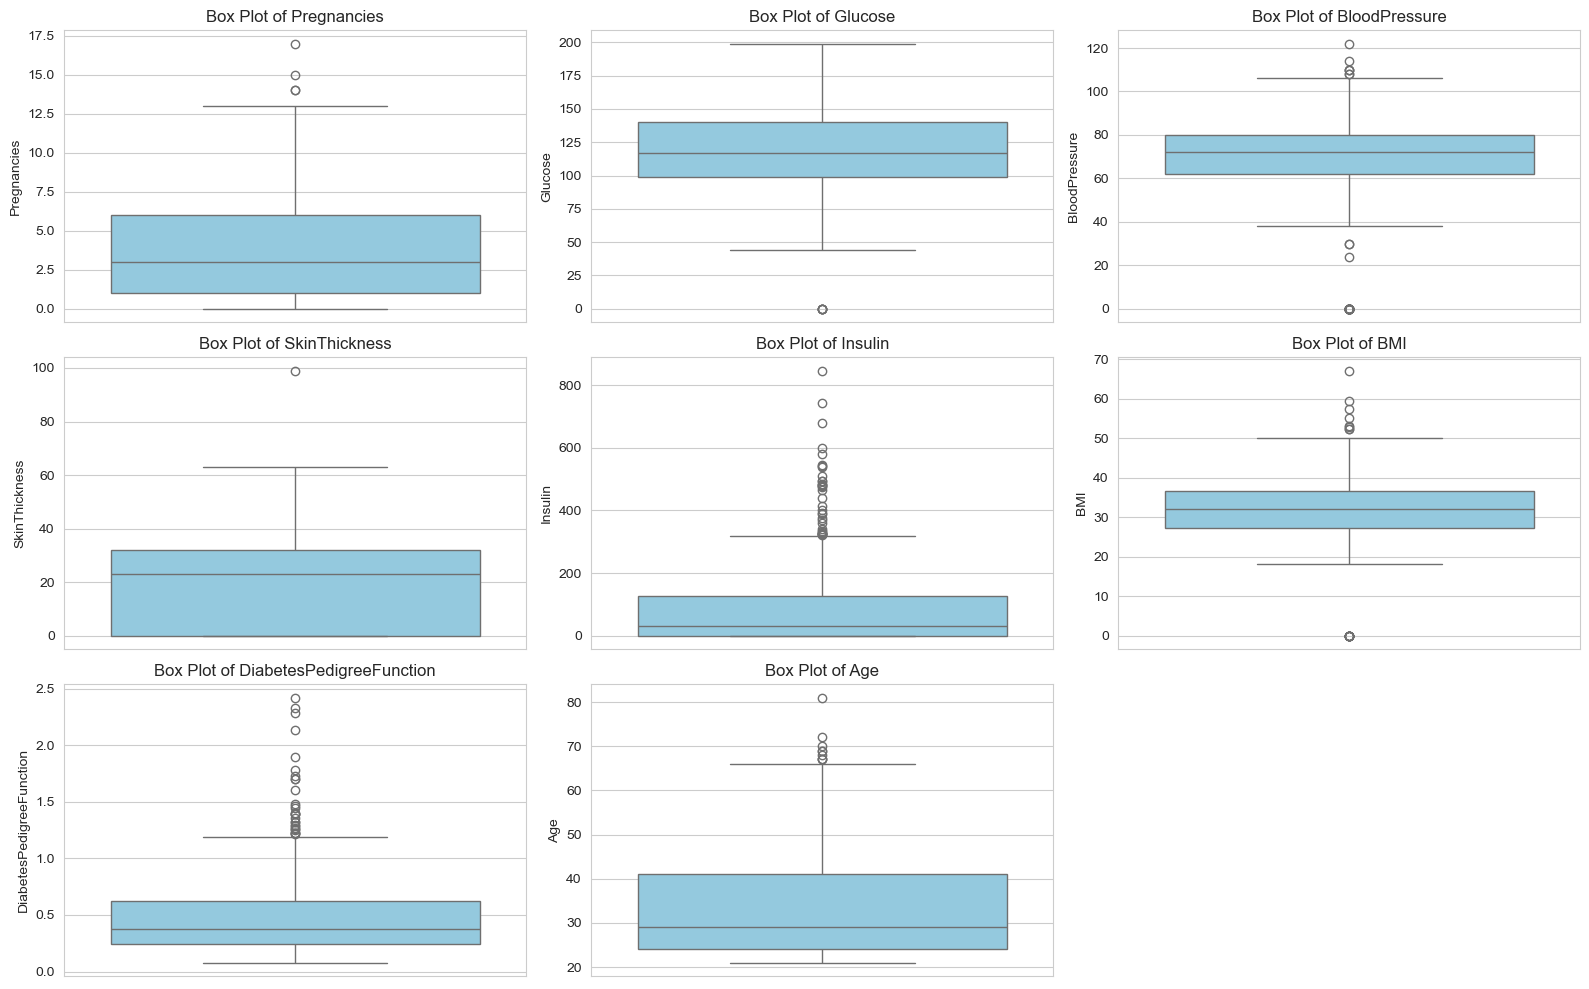

In [15]:
plt.figure(figsize=(16, 10))

for i, column in enumerate(df.columns[:-1], 1):

    plt.subplot(3, 3, i)

    sns.boxplot(
        y=df[column],
        color="skyblue"
    )

    plt.title(f"Box Plot of {column}")

plt.tight_layout()
plt.show()

Correlation heatmap

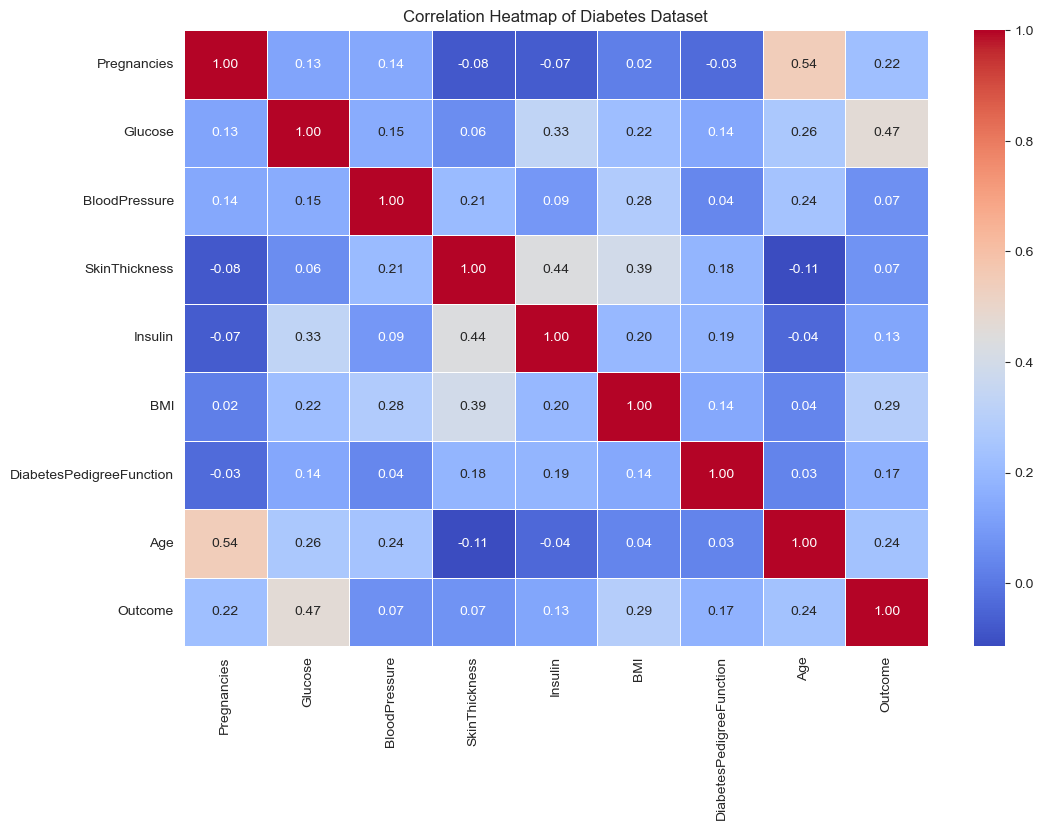

In [16]:
plt.figure(figsize=(12, 8))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Diabetes Dataset")

plt.show()

Feature relationship with diabetes outcome

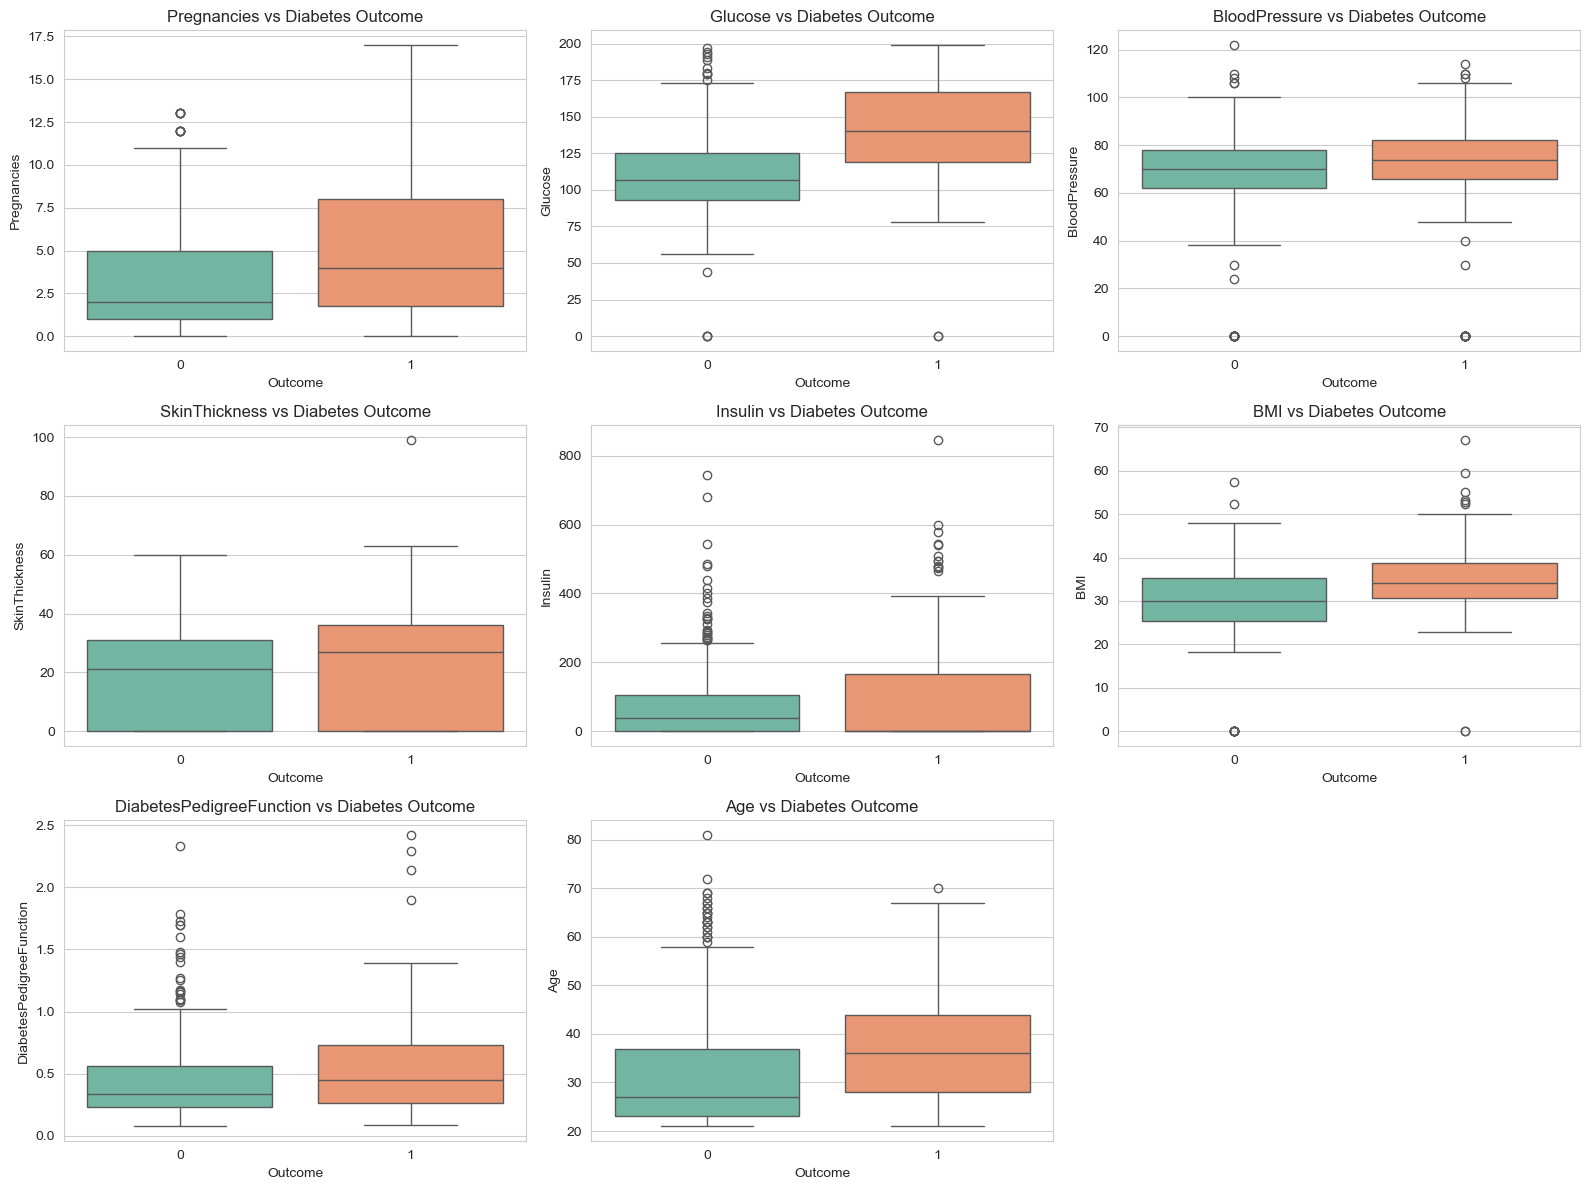

In [17]:
features = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

plt.figure(figsize=(16, 12))

for i, column in enumerate(features, 1):

    plt.subplot(3, 3, i)

    sns.boxplot(
        data=df,
        x="Outcome",
        y=column,
        hue="Outcome",
        palette="Set2",
        legend=False
    )

    plt.title(f"{column} vs Diabetes Outcome")

plt.tight_layout()
plt.show()

Scatter plots

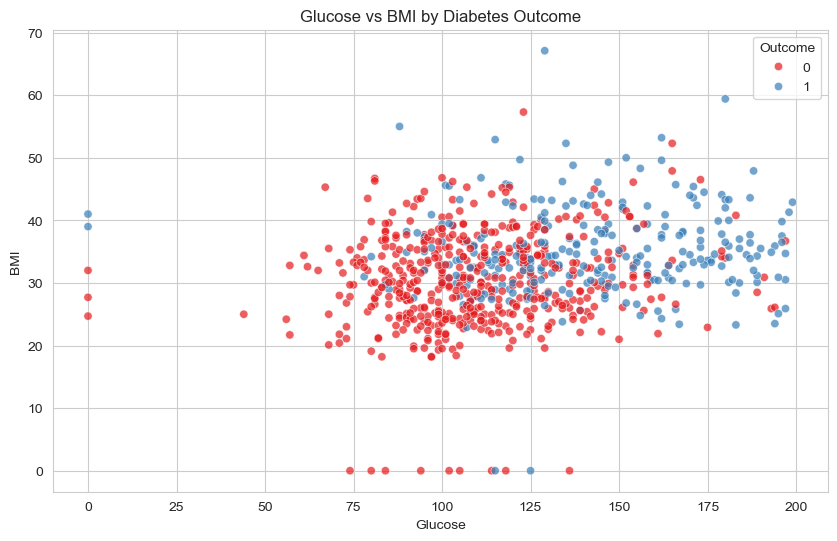

In [18]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Glucose",
    y="BMI",
    hue="Outcome",
    palette="Set1",
    alpha=0.7
)

plt.title("Glucose vs BMI by Diabetes Outcome")
plt.xlabel("Glucose")
plt.ylabel("BMI")

plt.show()

Age vs Glucose

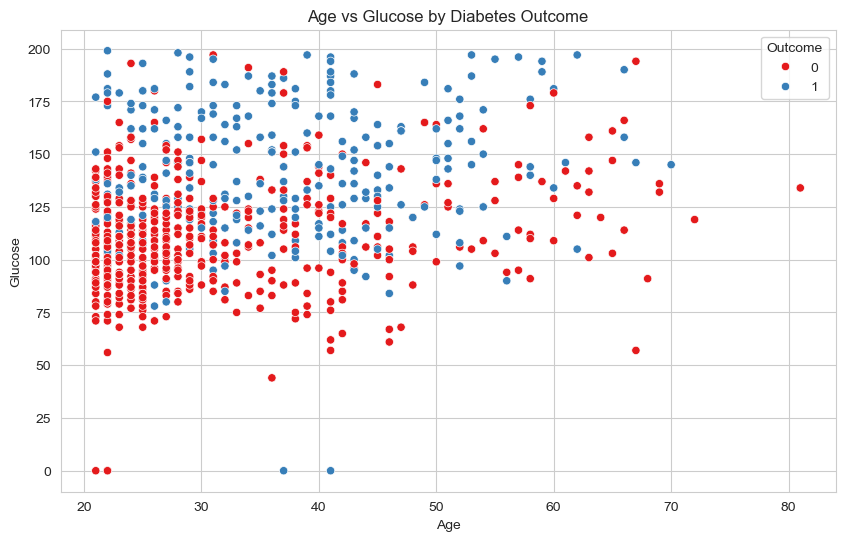

In [19]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Glucose",
    hue="Outcome",
    palette="Set1"
)

plt.title("Age vs Glucose by Diabetes Outcome")
plt.show()

Feature-wise average comparison

Outcome                            0           1
Pregnancies                 3.298000    4.865672
Glucose                   109.980000  141.257463
BloodPressure              68.184000   70.824627
SkinThickness              19.664000   22.164179
Insulin                    68.792000  100.335821
BMI                        30.304200   35.142537
DiabetesPedigreeFunction    0.429734    0.550500
Age                        31.190000   37.067164


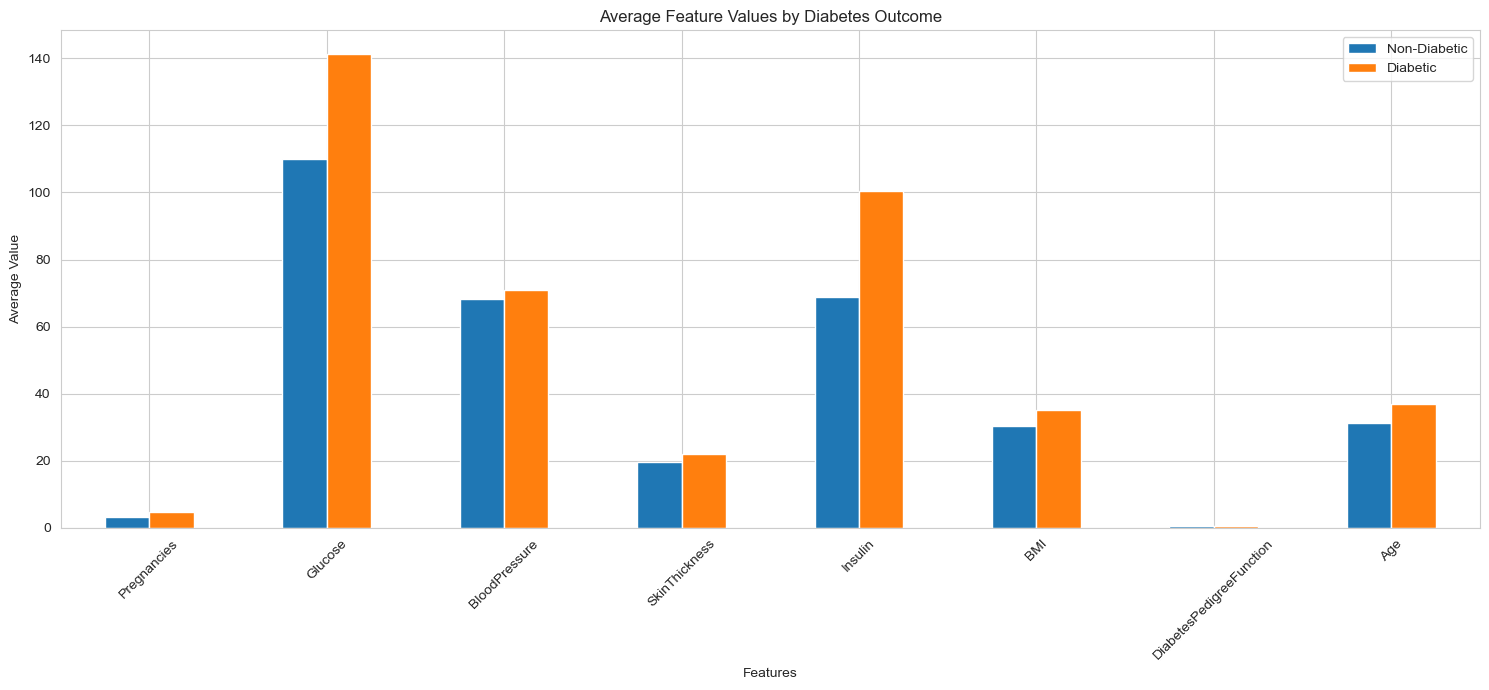

In [20]:
outcome_analysis = df.groupby("Outcome")[features].mean().T

print(outcome_analysis)

outcome_analysis.plot(
    kind="bar",
    figsize=(15, 7)
)

plt.title("Average Feature Values by Diabetes Outcome")
plt.xlabel("Features")
plt.ylabel("Average Value")

plt.xticks(rotation=45)
plt.legend(["Non-Diabetic", "Diabetic"])

plt.tight_layout()
plt.show()

PART 4 — Data Preprocessing

Check invalid zero values

In [21]:
# Features where zero represents a missing or invalid measurement
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Count zero values in each feature
for column in zero_columns:

    zero_count = (df[column] == 0).sum()

    print(f"{column}: {zero_count} zero values")

Glucose: 5 zero values
BloodPressure: 35 zero values
SkinThickness: 227 zero values
Insulin: 374 zero values
BMI: 11 zero values


Visualize invalid zero values

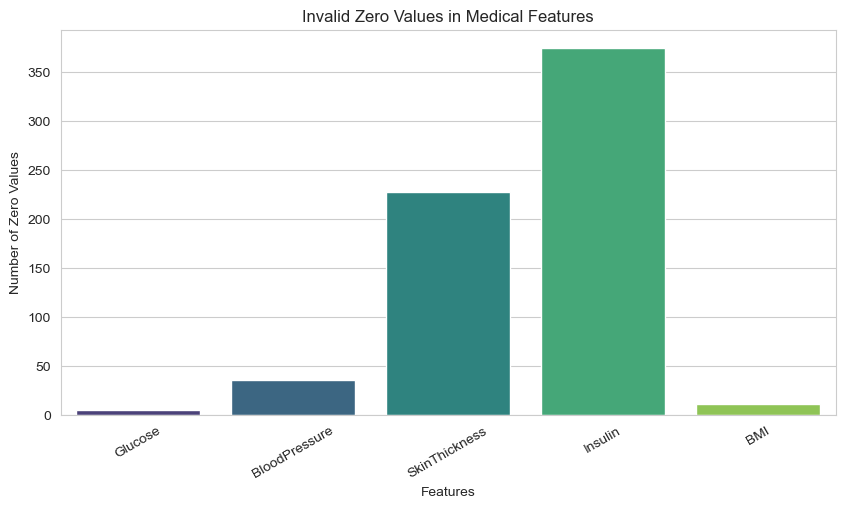

In [22]:
zero_counts = (df[zero_columns] == 0).sum()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=zero_counts.index,
    y=zero_counts.values,
    hue=zero_counts.index,
    palette="viridis",
    legend=False
)

plt.title("Invalid Zero Values in Medical Features")
plt.xlabel("Features")
plt.ylabel("Number of Zero Values")

plt.xticks(rotation=30)
plt.show()

Replace invalid zeros with NaN

In [23]:
# Create a copy of the original dataset
df_clean = df.copy()

# Replace invalid zeros with missing values
df_clean[zero_columns] = df_clean[zero_columns].replace(0, np.nan)

# Check missing values after replacement
print("Missing Values After Zero Replacement:")

print(df_clean.isnull().sum())

Missing Values After Zero Replacement:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


Remove duplicate records

In [24]:
# Remove duplicate records if present
df_clean = df_clean.drop_duplicates()

print("Dataset Shape After Removing Duplicates:")
print(df_clean.shape)

Dataset Shape After Removing Duplicates:
(768, 9)


Separate independent and dependent variables

In [25]:
# Independent variables
X = df_clean.drop("Outcome", axis=1)

# Dependent variable
y = df_clean["Outcome"]

print("Independent Variables Shape:", X.shape)
print("Dependent Variable Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Independent Variables Shape: (768, 8)
Dependent Variable Shape: (768,)

Target Distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


Train-test split

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

Training Data: (614, 8)
Testing Data: (154, 8)

Training Target Distribution:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64

Testing Target Distribution:
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


Handle missing values using median imputation

In [27]:
# Create median imputer
imputer = SimpleImputer(strategy="median")

# Fit imputer only on training data
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Transform testing data using the same imputer
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Missing Values in Training Data:")
print(X_train_imputed.isnull().sum().sum())

print("\nMissing Values in Testing Data:")
print(X_test_imputed.isnull().sum().sum())

Missing Values in Training Data:
0

Missing Values in Testing Data:
0


Check the final preprocessed dataset

In [28]:
print("Final Training Dataset:")
display(X_train_imputed.head())

print("\nFinal Testing Dataset:")
display(X_test_imputed.head())

print("\nFinal Dataset Information:")
print(X_train_imputed.info())

Final Training Dataset:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
353,1.0,90.0,62.0,12.0,43.0,27.2,0.580,24.0
711,5.0,126.0,78.0,27.0,22.0,29.6,0.439,40.0
373,2.0,105.0,58.0,40.0,94.0,34.9,0.225,25.0
46,1.0,146.0,56.0,29.0,125.0,29.7,0.564,29.0
682,0.0,95.0,64.0,39.0,105.0,44.6,0.366,22.0



Final Testing Dataset:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
44,7.0,159.0,64.0,29.0,125.0,27.4,0.294,40.0
672,10.0,68.0,106.0,23.0,49.0,35.5,0.285,47.0
700,2.0,122.0,76.0,27.0,200.0,35.9,0.483,26.0
630,7.0,114.0,64.0,29.0,125.0,27.4,0.732,34.0
81,2.0,74.0,72.0,29.0,125.0,32.4,0.102,22.0



Final Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 614 entries, 353 to 107
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               614 non-null    float64
 1   Glucose                   614 non-null    float64
 2   BloodPressure             614 non-null    float64
 3   SkinThickness             614 non-null    float64
 4   Insulin                   614 non-null    float64
 5   BMI                       614 non-null    float64
 6   DiabetesPedigreeFunction  614 non-null    float64
 7   Age                       614 non-null    float64
dtypes: float64(8)
memory usage: 43.2 KB
None


PART 5 — Build LightGBM Model

Train LightGBM classifier

In [29]:
# Create LightGBM model pipeline
lgbm_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("classifier", LGBMClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=15,
        random_state=42,
        verbosity=-1
    ))
])

# Train the model
lgbm_model.fit(X_train, y_train)

print("LightGBM Model Training Completed!")

  File "c:\Users\yashr\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\yashr\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\yashr\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\yashr\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


LightGBM Model Training Completed!


Make predictions

In [30]:
# Predict test dataset
lgbm_predictions = lgbm_model.predict(X_test)

# Predict probabilities
lgbm_probabilities = lgbm_model.predict_proba(X_test)[:, 1]

print("LightGBM Predictions:")
print(lgbm_predictions[:20])

LightGBM Predictions:
[1 0 0 1 0 0 0 1 0 1 1 1 0 0 0 0 1 0 1 0]


Evaluate LightGBM model

In [31]:
# Calculate evaluation metrics
lgbm_accuracy = accuracy_score(
    y_test,
    lgbm_predictions
)

lgbm_precision = precision_score(
    y_test,
    lgbm_predictions,
    zero_division=0
)

lgbm_recall = recall_score(
    y_test,
    lgbm_predictions,
    zero_division=0
)

lgbm_f1 = f1_score(
    y_test,
    lgbm_predictions,
    zero_division=0
)

lgbm_roc_auc = roc_auc_score(
    y_test,
    lgbm_probabilities
)

print("LIGHTGBM PERFORMANCE")

print("Accuracy :", round(lgbm_accuracy, 4))
print("Precision:", round(lgbm_precision, 4))
print("Recall   :", round(lgbm_recall, 4))
print("F1 Score :", round(lgbm_f1, 4))
print("ROC-AUC  :", round(lgbm_roc_auc, 4))

LIGHTGBM PERFORMANCE
Accuracy : 0.7597
Precision: 0.6667
Recall   : 0.6296
F1 Score : 0.6476
ROC-AUC  : 0.817


Classification report

In [32]:
print("LightGBM Classification Report:\n")

print(
    classification_report(
        y_test,
        lgbm_predictions,
        target_names=[
            "Non-Diabetic",
            "Diabetic"
        ],
        zero_division=0
    )
)

LightGBM Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       0.81      0.83      0.82       100
    Diabetic       0.67      0.63      0.65        54

    accuracy                           0.76       154
   macro avg       0.74      0.73      0.73       154
weighted avg       0.76      0.76      0.76       154



Confusion matrix

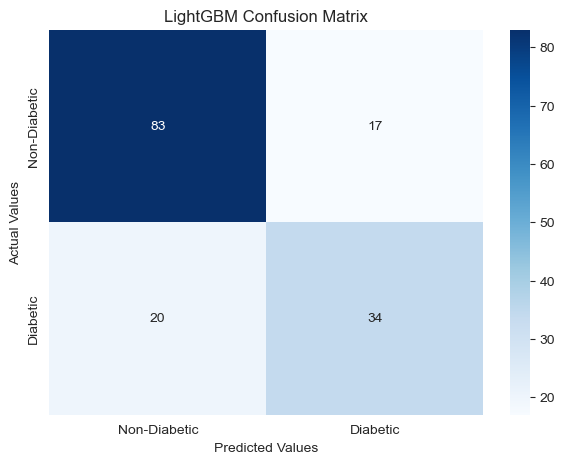

In [33]:
lgbm_cm = confusion_matrix(
    y_test,
    lgbm_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    lgbm_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Diabetic", "Diabetic"],
    yticklabels=["Non-Diabetic", "Diabetic"]
)

plt.title("LightGBM Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

PART 6 — Build XGBoost Model

Train XGBoost classifier

In [34]:
# Create XGBoost model pipeline
xgb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("classifier", XGBClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Train XGBoost model
xgb_model.fit(X_train, y_train)

print("XGBoost Model Training Completed!")

XGBoost Model Training Completed!


Make prediction

In [35]:
# Predict test data
xgb_predictions = xgb_model.predict(X_test)

# Predict probability of diabetes
xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost Predictions:")
print(xgb_predictions[:20])

XGBoost Predictions:
[1 0 0 0 0 0 1 1 0 1 0 1 0 0 0 0 1 0 1 0]


Evaluate XGBoost model

In [36]:
# Calculate evaluation metrics
xgb_accuracy = accuracy_score(
    y_test,
    xgb_predictions
)

xgb_precision = precision_score(
    y_test,
    xgb_predictions,
    zero_division=0
)

xgb_recall = recall_score(
    y_test,
    xgb_predictions,
    zero_division=0
)

xgb_f1 = f1_score(
    y_test,
    xgb_predictions,
    zero_division=0
)

xgb_roc_auc = roc_auc_score(
    y_test,
    xgb_probabilities
)

print("XGBOOST PERFORMANCE")

print("Accuracy :", round(xgb_accuracy, 4))
print("Precision:", round(xgb_precision, 4))
print("Recall   :", round(xgb_recall, 4))
print("F1 Score :", round(xgb_f1, 4))
print("ROC-AUC  :", round(xgb_roc_auc, 4))

XGBOOST PERFORMANCE
Accuracy : 0.7662
Precision: 0.6957
Recall   : 0.5926
F1 Score : 0.64
ROC-AUC  : 0.8269


Classification report

In [37]:
print("XGBoost Classification Report:\n")

print(
    classification_report(
        y_test,
        xgb_predictions,
        target_names=[
            "Non-Diabetic",
            "Diabetic"
        ],
        zero_division=0
    )
)

XGBoost Classification Report:

              precision    recall  f1-score   support

Non-Diabetic       0.80      0.86      0.83       100
    Diabetic       0.70      0.59      0.64        54

    accuracy                           0.77       154
   macro avg       0.75      0.73      0.73       154
weighted avg       0.76      0.77      0.76       154



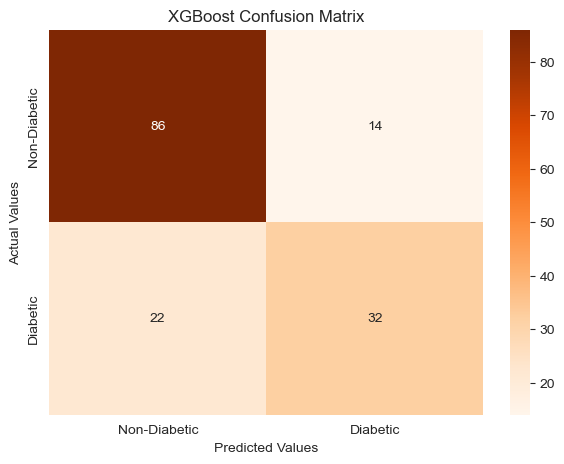

In [38]:
xgb_cm = confusion_matrix(
    y_test,
    xgb_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    xgb_cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Non-Diabetic", "Diabetic"],
    yticklabels=["Non-Diabetic", "Diabetic"]
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

PART 7 — Cross-Validation

In [40]:
# Create stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

Cross-validation for LightGBM

In [41]:
lgbm_cv_results = cross_validate(
    lgbm_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("LIGHTGBM CROSS-VALIDATION")

for metric in scoring:

    scores = lgbm_cv_results[
        f"test_{metric}"
    ]

    print(
        f"{metric.upper()}: "
        f"{scores.mean():.4f} "
        f"+/- {scores.std():.4f}"
    )

LIGHTGBM CROSS-VALIDATION
ACCURACY: 0.7574 +/- 0.0230
PRECISION: 0.6731 +/- 0.0461
RECALL: 0.5983 +/- 0.0282
F1: 0.6326 +/- 0.0271
ROC_AUC: 0.8141 +/- 0.0249


Cross-validation for XGBoost

In [42]:
xgb_cv_results = cross_validate(
    xgb_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("XGBOOST CROSS-VALIDATION")

for metric in scoring:

    scores = xgb_cv_results[
        f"test_{metric}"
    ]

    print(
        f"{metric.upper()}: "
        f"{scores.mean():.4f} "
        f"+/- {scores.std():.4f}"
    )

XGBOOST CROSS-VALIDATION
ACCURACY: 0.7720 +/- 0.0309
PRECISION: 0.7114 +/- 0.0774
RECALL: 0.5982 +/- 0.0255
F1: 0.6477 +/- 0.0341
ROC_AUC: 0.8331 +/- 0.0241


PART 8 — Hyperparameter Tuning

LightGBM hyperparameter tuning

In [43]:
# Define LightGBM parameter grid
lgbm_param_grid = {
    "classifier__n_estimators": [100, 200, 300, 400],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__max_depth": [-1, 3, 5, 7],
    "classifier__num_leaves": [7, 15, 20, 31],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

# Randomized search
lgbm_search = RandomizedSearchCV(
    estimator=lgbm_model,
    param_distributions=lgbm_param_grid,
    n_iter=15,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit search on training data
lgbm_search.fit(X_train, y_train)

print("Best LightGBM Parameters:")
print(lgbm_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(lgbm_search.best_score_)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best LightGBM Parameters:
{'classifier__subsample': 0.9, 'classifier__num_leaves': 20, 'classifier__n_estimators': 300, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.01, 'classifier__colsample_bytree': 0.8}

Best Cross-Validation ROC-AUC:
0.8363995016611296


Best LightGBM model

In [44]:
# Retrieve the best LightGBM model
best_lgbm_model = lgbm_search.best_estimator_

print("Best LightGBM Model:")
print(best_lgbm_model)

Best LightGBM Model:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier',
                 LGBMClassifier(colsample_bytree=0.8, learning_rate=0.01,
                                max_depth=3, n_estimators=300, num_leaves=20,
                                random_state=42, subsample=0.9,
                                verbosity=-1))])


XGBoost hyperparameter tuning

In [45]:
# Define XGBoost parameter grid
xgb_param_grid = {
    "classifier__n_estimators": [100, 200, 300, 400],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__max_depth": [2, 3, 4, 5, 6],
    "classifier__min_child_weight": [1, 3, 5],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__gamma": [0, 0.1, 0.2, 0.3]
}

# Randomized search
xgb_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=xgb_param_grid,
    n_iter=15,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit search on training data
xgb_search.fit(X_train, y_train)

print("Best XGBoost Parameters:")
print(xgb_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(xgb_search.best_score_)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best XGBoost Parameters:
{'classifier__subsample': 0.7, 'classifier__n_estimators': 200, 'classifier__min_child_weight': 3, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.01, 'classifier__gamma': 0, 'classifier__colsample_bytree': 1.0}

Best Cross-Validation ROC-AUC:
0.835921926910299


Best XGBoost model

In [46]:
# Retrieve the best XGBoost model
best_xgb_model = xgb_search.best_estimator_

print("Best XGBoost Model:")
print(best_xgb_model)

Best XGBoost Model:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=1.0, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='logloss',
                               feature_types=None, feature_weights=None,
                               gamma=0, grow_policy=None, importance_type=None,
                               interaction_constraints=None, learning_rate=0.01,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None, min_child_weight=3,
                               missing=nan, monotone_constraints=N

Evaluate tuned models

In [47]:
# LightGBM predictions
best_lgbm_predictions = best_lgbm_model.predict(X_test)

best_lgbm_probabilities = (
    best_lgbm_model.predict_proba(X_test)[:, 1]
)

# XGBoost predictions
best_xgb_predictions = best_xgb_model.predict(X_test)

best_xgb_probabilities = (
    best_xgb_model.predict_proba(X_test)[:, 1]
)

print("Tuned models evaluated successfully!")

Tuned models evaluated successfully!


In [48]:
def evaluate_model(y_true, predictions, probabilities):

    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        )
    }


# Evaluate tuned LightGBM
tuned_lgbm_metrics = evaluate_model(
    y_test,
    best_lgbm_predictions,
    best_lgbm_probabilities
)

# Evaluate tuned XGBoost
tuned_xgb_metrics = evaluate_model(
    y_test,
    best_xgb_predictions,
    best_xgb_probabilities
)

print("Tuned LightGBM:")
print(tuned_lgbm_metrics)

print("\nTuned XGBoost:")
print(tuned_xgb_metrics)

Tuned LightGBM:
{'Accuracy': 0.7402597402597403, 'Precision': 0.6521739130434783, 'Recall': 0.5555555555555556, 'F1 Score': 0.6, 'ROC-AUC': 0.8168518518518518}

Tuned XGBoost:
{'Accuracy': 0.7402597402597403, 'Precision': 0.6590909090909091, 'Recall': 0.5370370370370371, 'F1 Score': 0.5918367346938775, 'ROC-AUC': 0.8255555555555556}


PART 9 — Comparative Performance Analysis

Create comparison table

In [49]:
# Create comparison DataFrame
comparison_df = pd.DataFrame({
    "LightGBM": tuned_lgbm_metrics,
    "XGBoost": tuned_xgb_metrics
})

print("MODEL PERFORMANCE COMPARISON")

display(comparison_df.round(4))

MODEL PERFORMANCE COMPARISON


,LightGBM,XGBoost
Accuracy,0.7403,0.7403
Precision,0.6522,0.6591
Recall,0.5556,0.5370
F1 Score,0.6000,0.5918
ROC-AUC,0.8169,0.8256


Performance comparison chart


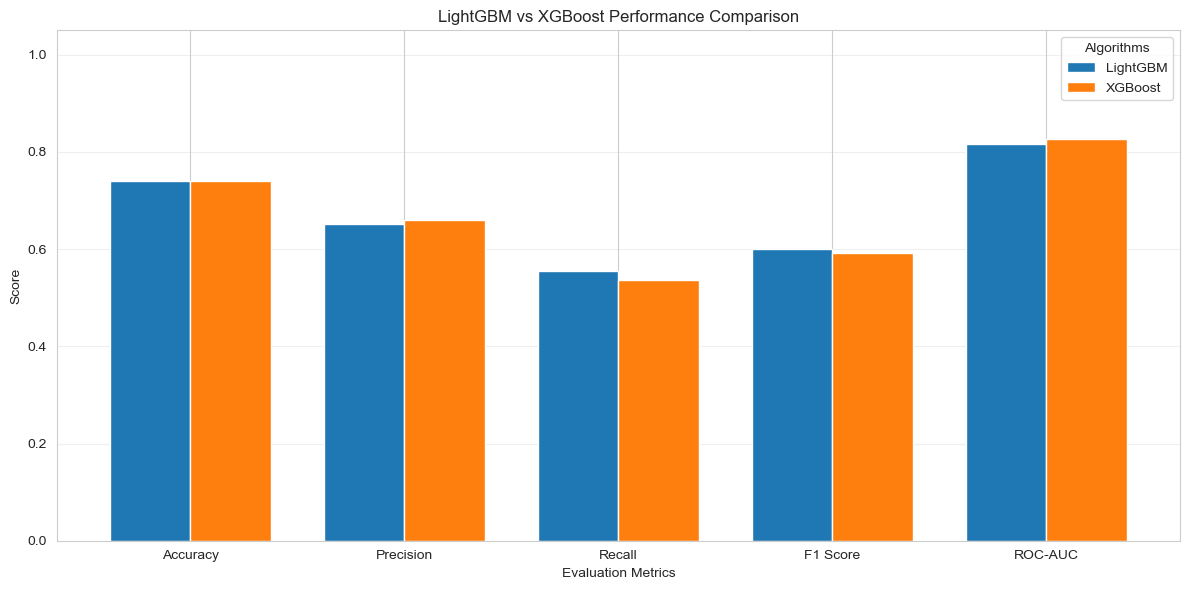

In [50]:
comparison_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

plt.title("LightGBM vs XGBoost Performance Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=0)
plt.legend(title="Algorithms")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Accuracy comparison

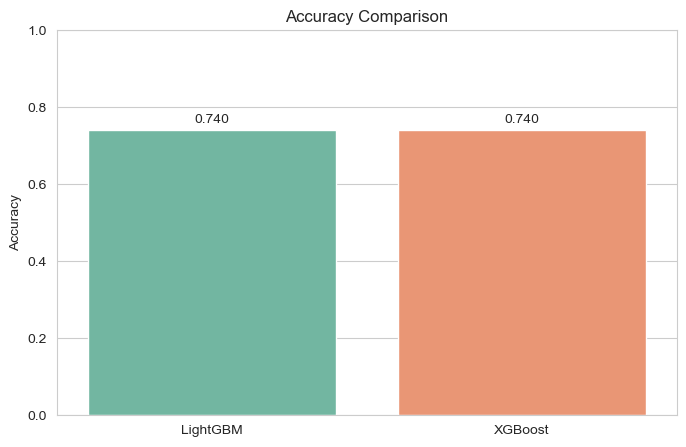

In [51]:
accuracy_values = [
    tuned_lgbm_metrics["Accuracy"],
    tuned_xgb_metrics["Accuracy"]
]

model_names = [
    "LightGBM",
    "XGBoost"
]

plt.figure(figsize=(8, 5))

sns.barplot(
    x=model_names,
    y=accuracy_values,
    hue=model_names,
    palette="Set2",
    legend=False
)

plt.title("Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

for i, value in enumerate(accuracy_values):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.show()

ROC curve comparison

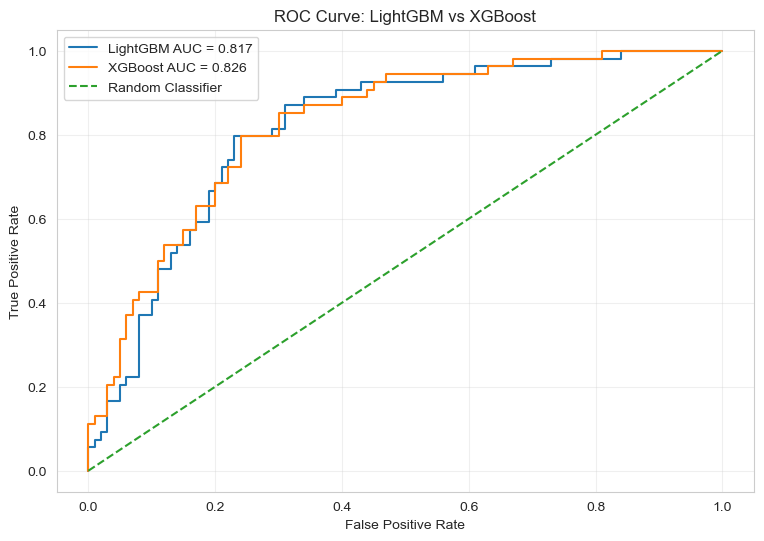

In [52]:
# Calculate ROC curve for LightGBM
lgbm_fpr, lgbm_tpr, _ = roc_curve(
    y_test,
    best_lgbm_probabilities
)

# Calculate ROC curve for XGBoost
xgb_fpr, xgb_tpr, _ = roc_curve(
    y_test,
    best_xgb_probabilities
)

plt.figure(figsize=(9, 6))

plt.plot(
    lgbm_fpr,
    lgbm_tpr,
    label=f"LightGBM AUC = {tuned_lgbm_metrics['ROC-AUC']:.3f}"
)

plt.plot(
    xgb_fpr,
    xgb_tpr,
    label=f"XGBoost AUC = {tuned_xgb_metrics['ROC-AUC']:.3f}"
)

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve: LightGBM vs XGBoost")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

Compare confusion matrices

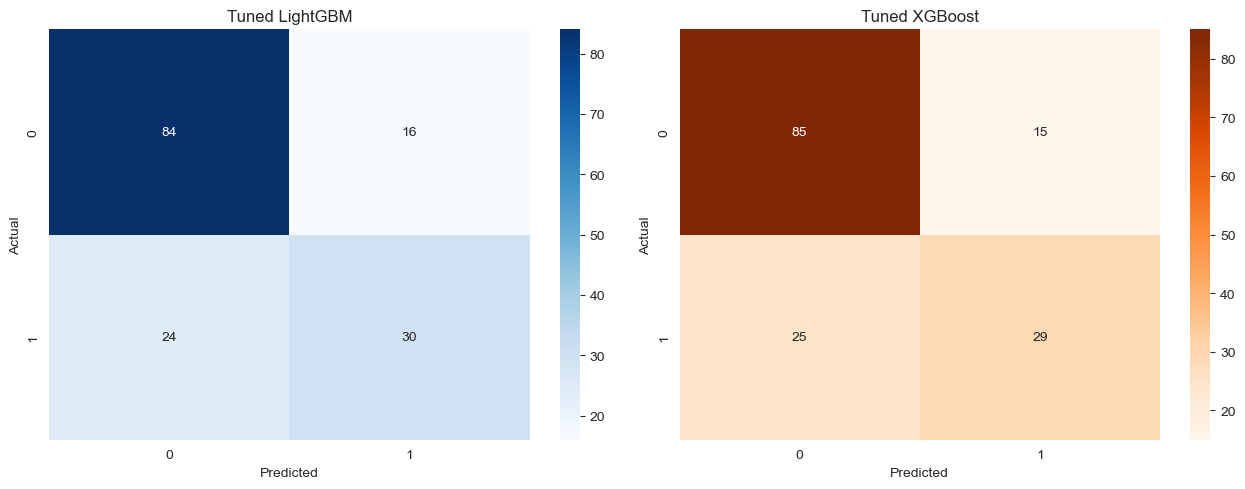

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# LightGBM confusion matrix
sns.heatmap(
    confusion_matrix(y_test, best_lgbm_predictions),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Tuned LightGBM")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# XGBoost confusion matrix
sns.heatmap(
    confusion_matrix(y_test, best_xgb_predictions),
    annot=True,
    fmt="d",
    cmap="Oranges",
    ax=axes[1]
)

axes[1].set_title("Tuned XGBoost")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

Feature importance comparison


In [54]:
# Extract feature importance
lgbm_importance = (
    best_lgbm_model
    .named_steps["classifier"]
    .feature_importances_
)

xgb_importance = (
    best_xgb_model
    .named_steps["classifier"]
    .feature_importances_
)

# Create importance DataFrame
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "LightGBM": lgbm_importance,
    "XGBoost": xgb_importance
})

# Normalize feature importance for easier comparison
importance_df["LightGBM"] = (
    importance_df["LightGBM"] /
    importance_df["LightGBM"].sum()
)

importance_df["XGBoost"] = (
    importance_df["XGBoost"] /
    importance_df["XGBoost"].sum()
)

display(
    importance_df.sort_values(
        "LightGBM",
        ascending=False
    ).round(4)
)

,Feature,LightGBM,XGBoost
1,Glucose,0.2541,0.3255
5,BMI,0.2170,0.1450
7,Age,0.1514,0.1239
6,DiabetesPedigreeFunction,0.1435,0.0802
0,Pregnancies,0.0932,0.0949
3,SkinThickness,0.0588,0.0687
4,Insulin,0.0577,0.1075
2,BloodPressure,0.0244,0.0542


Feature importance visualization

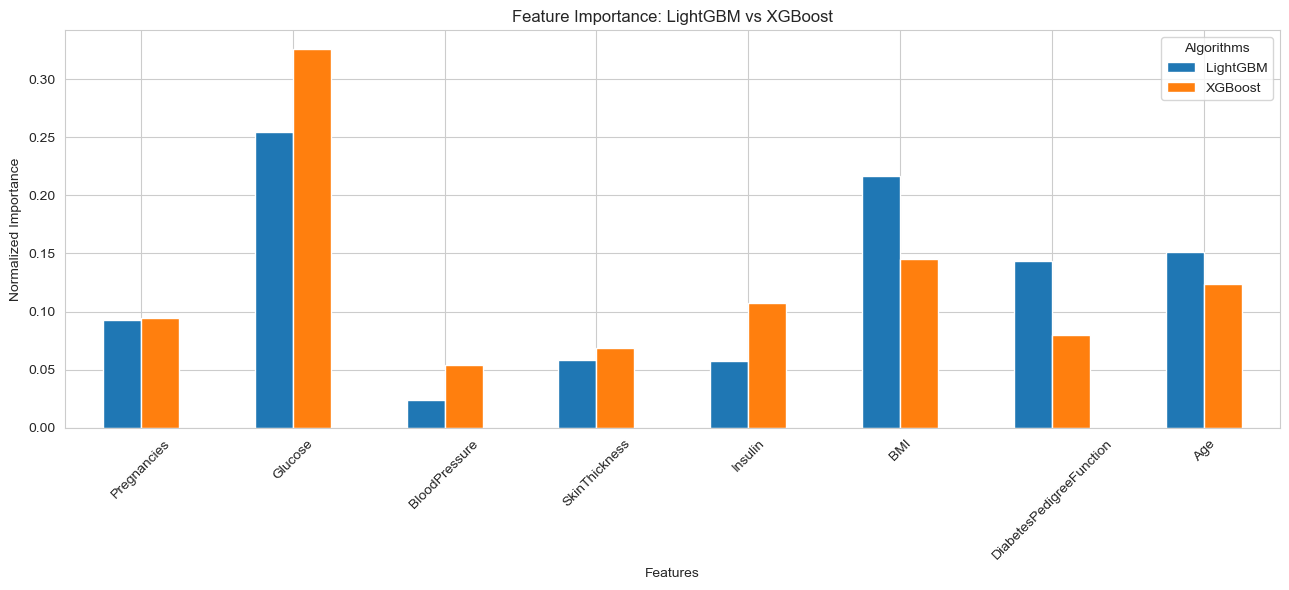

In [55]:
importance_plot = importance_df.set_index("Feature")

importance_plot.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Feature Importance: LightGBM vs XGBoost")
plt.xlabel("Features")
plt.ylabel("Normalized Importance")

plt.xticks(rotation=45)
plt.legend(title="Algorithms")

plt.tight_layout()
plt.show()

PART 10 — Detailed Interpretation of Results

Automatically identify the better-performing model

In [56]:
# Compare model performance using ROC-AUC
if tuned_lgbm_metrics["ROC-AUC"] > tuned_xgb_metrics["ROC-AUC"]:

    print("LightGBM has better ROC-AUC performance.")

elif tuned_xgb_metrics["ROC-AUC"] > tuned_lgbm_metrics["ROC-AUC"]:

    print("XGBoost has better ROC-AUC performance.")

else:

    print("Both models have equal ROC-AUC performance.")


# Compare accuracy
if tuned_lgbm_metrics["Accuracy"] > tuned_xgb_metrics["Accuracy"]:

    print("LightGBM has higher accuracy.")

elif tuned_xgb_metrics["Accuracy"] > tuned_lgbm_metrics["Accuracy"]:

    print("XGBoost has higher accuracy.")

else:

    print("Both models have equal accuracy.")

XGBoost has better ROC-AUC performance.
Both models have equal accuracy.


Automatically identify the best model for each metric

In [57]:
print("BEST MODEL ACCORDING TO EACH METRIC\n")

for metric in comparison_df.index:

    best_model = comparison_df.loc[metric].idxmax()

    best_score = comparison_df.loc[metric].max()

    print(
        f"{metric}: {best_model} "
        f"({best_score:.4f})"
    )

BEST MODEL ACCORDING TO EACH METRIC

Accuracy: LightGBM (0.7403)
Precision: XGBoost (0.6591)
Recall: LightGBM (0.5556)
F1 Score: LightGBM (0.6000)
ROC-AUC: XGBoost (0.8256)


Compare cross-validation stability

In [58]:
cv_comparison = pd.DataFrame({
    "LightGBM Mean ROC-AUC": [
        lgbm_cv_results["test_roc_auc"].mean()
    ],

    "LightGBM Std ROC-AUC": [
        lgbm_cv_results["test_roc_auc"].std()
    ],

    "XGBoost Mean ROC-AUC": [
        xgb_cv_results["test_roc_auc"].mean()
    ],

    "XGBoost Std ROC-AUC": [
        xgb_cv_results["test_roc_auc"].std()
    ]
})

display(cv_comparison.round(4))

,LightGBM Mean ROC-AUC,LightGBM Std ROC-AUC,XGBoost Mean ROC-AUC,XGBoost Std ROC-AUC
0,0.8141,0.0249,0.8331,0.0241


Print final model comparison

In [59]:
print("=" * 60)
print("FINAL MODEL COMPARISON")
print("=" * 60)

print("\nLIGHTGBM")

for metric, value in tuned_lgbm_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nXGBOOST")

for metric, value in tuned_xgb_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\n" + "=" * 60)

best_model_name = comparison_df.loc[
    "ROC-AUC"
].idxmax()

print("BEST MODEL BASED ON TEST ROC-AUC:", best_model_name)

print("=" * 60)

FINAL MODEL COMPARISON

LIGHTGBM
Accuracy: 0.7403
Precision: 0.6522
Recall: 0.5556
F1 Score: 0.6000
ROC-AUC: 0.8169

XGBOOST
Accuracy: 0.7403
Precision: 0.6591
Recall: 0.5370
F1 Score: 0.5918
ROC-AUC: 0.8256

BEST MODEL BASED ON TEST ROC-AUC: XGBoost


Final Output

In [60]:
# Save model comparison table
comparison_df.to_csv(
    "diabetes_model_comparison.csv"
)

# Save feature importance
importance_df.to_csv(
    "diabetes_feature_importance.csv",
    index=False
)

print("Comparison results saved successfully!")

Comparison results saved successfully!


Generate final project summary

In [61]:
print("=" * 65)
print("DIABETES PREDICTION - FINAL PROJECT SUMMARY")
print("=" * 65)

print("\nDataset Information")
print("Total Records:", len(df_clean))
print("Total Features:", len(features))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nLightGBM Performance")
for metric, value in tuned_lgbm_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nXGBoost Performance")
for metric, value in tuned_xgb_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nBest Model Based on ROC-AUC:")
print(comparison_df.loc["ROC-AUC"].idxmax())

print("\nProject Completed Successfully!")
print("=" * 65)

DIABETES PREDICTION - FINAL PROJECT SUMMARY

Dataset Information
Total Records: 768
Total Features: 8
Training Records: 614
Testing Records: 154

LightGBM Performance
Accuracy: 0.7403
Precision: 0.6522
Recall: 0.5556
F1 Score: 0.6000
ROC-AUC: 0.8169

XGBoost Performance
Accuracy: 0.7403
Precision: 0.6591
Recall: 0.5370
F1 Score: 0.5918
ROC-AUC: 0.8256

Best Model Based on ROC-AUC:
XGBoost

Project Completed Successfully!
